In [1]:
# ============================ CORE IMPORTS ============================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams          # for ease of resizing plots

from numpy import random
random.seed(10)                          # pre-setting seed

from scipy import stats, optimize        # optimize: used for Box-Cox calculations
from scipy.stats import norm

# For model fitting
import statsmodels.api as sm
import statsmodels.stats.api as sms      # NOTE: `sms` always means statsmodels.stats.api
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn import preprocessing, metrics

%matplotlib inline
rcParams['figure.figsize'] = (7, 4.5)
rcParams['figure.dpi'] = 110
pd.set_option('display.width', 120)

# ====================== OPTIONAL PACKAGES (never fatal) ======================
# Nothing below is required to run the lecture; each cell that uses them checks first.
try:
    from fitter import Fitter
    HAS_FITTER = True
except Exception as err:                 # pip install fitter
    Fitter, HAS_FITTER = None, False
    print(f'[optional] `fitter` unavailable ({type(err).__name__}) - those cells will self-skip.')

try:
    import wooldridge as woo
    HAS_WOO = True
except Exception:                        # pip install wooldridge
    woo, HAS_WOO = None, False
    print('[optional] `wooldridge` unavailable - Section 7 falls back to data/wage1.csv.')

# NOTE: rpy2 / the R kernel is NO LONGER imported anywhere in this notebook.
#       Every former `%%R` cell now has a native Python implementation.
print(f'numpy {np.__version__} | pandas {pd.__version__} | scipy {stats.__name__.split(".")[0]} '
      f'{__import__("scipy").__version__} | statsmodels {sm.__version__} | seaborn {sns.__version__} '
      f'| sklearn {__import__("sklearn").__version__}')

[optional] `fitter` unavailable (ModuleNotFoundError) - those cells will self-skip.
[optional] `wooldridge` unavailable - Section 7 falls back to data/wage1.csv.
numpy 2.4.6 | pandas 3.0.3 | scipy scipy 1.18.0 | statsmodels 0.14.6 | seaborn 0.13.2 | sklearn 1.9.0


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Resolve path whether kernel runs from Visualization/ or project root
data_path = Path('../data/processed/parking_cross_section.csv')
if not data_path.exists():
    data_path = Path('data/processed/parking_cross_section.csv')

raw = pd.read_csv(data_path, dtype={'SpaceID': str, 'GEOID': str})
print(f'Loaded: {raw.shape[0]:,} rows, {raw.shape[1]} columns')
raw.head()


Loaded: 4,139 rows, 36 columns


,SpaceID,occupancy_rate,occupied_minutes,total_minutes,active_days,BlockFace,MeterType,RateType,RateRange,MeteredTimeLimit,...,transit_share,walk_share,nearby_business_count,nearby_restaurant_retail_count,zoning_code,zoning_class,zoning_description,tract_match_status,acs_match_status,zoning_match_status
0,61111,0.515520,19511.316667,37847.833333,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,358,45,NaN,NaN,NaN,matched,matched,unmatched
1,61112,0.468853,17954.033333,38293.550000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,368,46,NaN,NaN,NaN,matched,matched,unmatched
2,61113,0.540309,21939.050000,40604.650000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,47,NaN,NaN,NaN,matched,matched,unmatched
3,61114,0.594108,26049.100000,43845.700000,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,46,NaN,NaN,NaN,matched,matched,unmatched
4,61116,0.524689,22993.916667,43823.916667,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,375,47,NaN,NaN,NaN,matched,matched,unmatched


In [109]:
log = []
df = raw.copy()
n_start = len(work)

print(f'{"starting records n = "}{n_start}')

starting records n = 4139


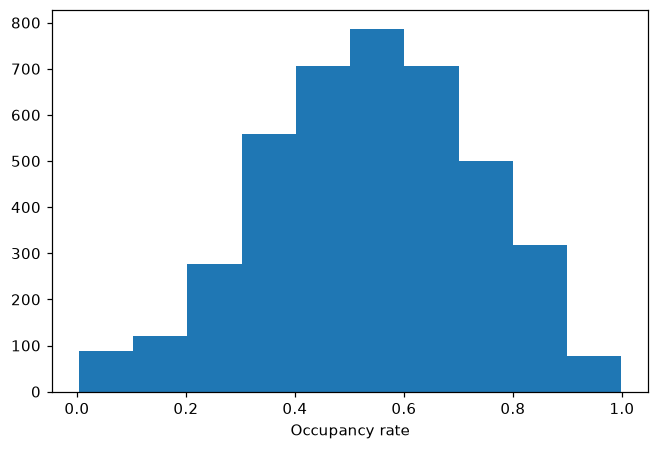

In [111]:
num_cols = ['occupancy_rate', 'price_midpoint']

summary = df[num_cols].agg(['count', 'mean', 'std', 'min', 'median', 'max']).T

x = df["occupancy_rate"].dropna()

fig, ax = plt.subplots()

ax.hist(df['occupancy_rate'])
ax.set_xlabel("Occupancy rate")
plt.show()

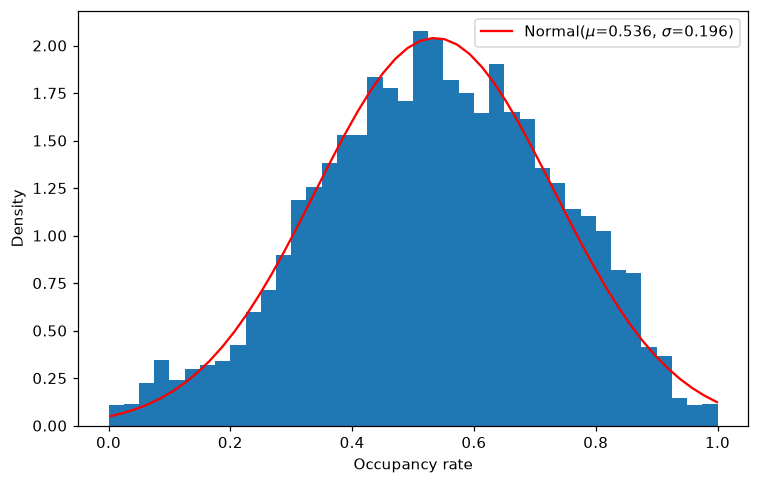

In [112]:
fig, ax = plt.subplots()


# density=True so the histogram is on the same scale as the pdf
ax.hist(x, bins=np.arange(0, 1.025, 0.025), density=True)
mu, sigma = x.mean(), x.std(ddof=1)
grid = np.linspace(x.min(), x.max())
ax.plot(grid, norm.pdf(grid, mu, sigma), color = "red",
      label=f"Normal($\\mu$={mu:.3f}, $\\sigma$={sigma:.3f})")

ax.set_xlabel("Occupancy rate")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

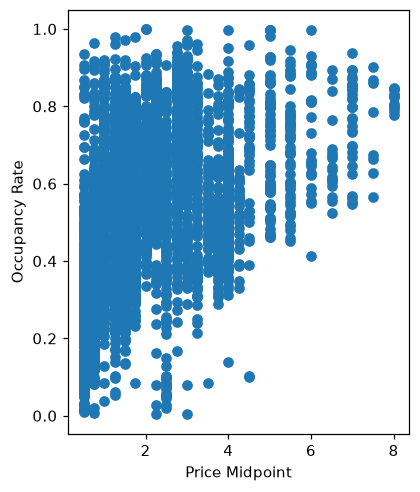

In [ ]:
fig, ax = plt.subplots(figsize=( 4, 5))
ax.scatter(df['price_midpoint'],  df['occupancy_rate'])
ax.set_xlabel('Price Midpoint')
ax.set_ylabel('Occupancy Rate')
plt.show()

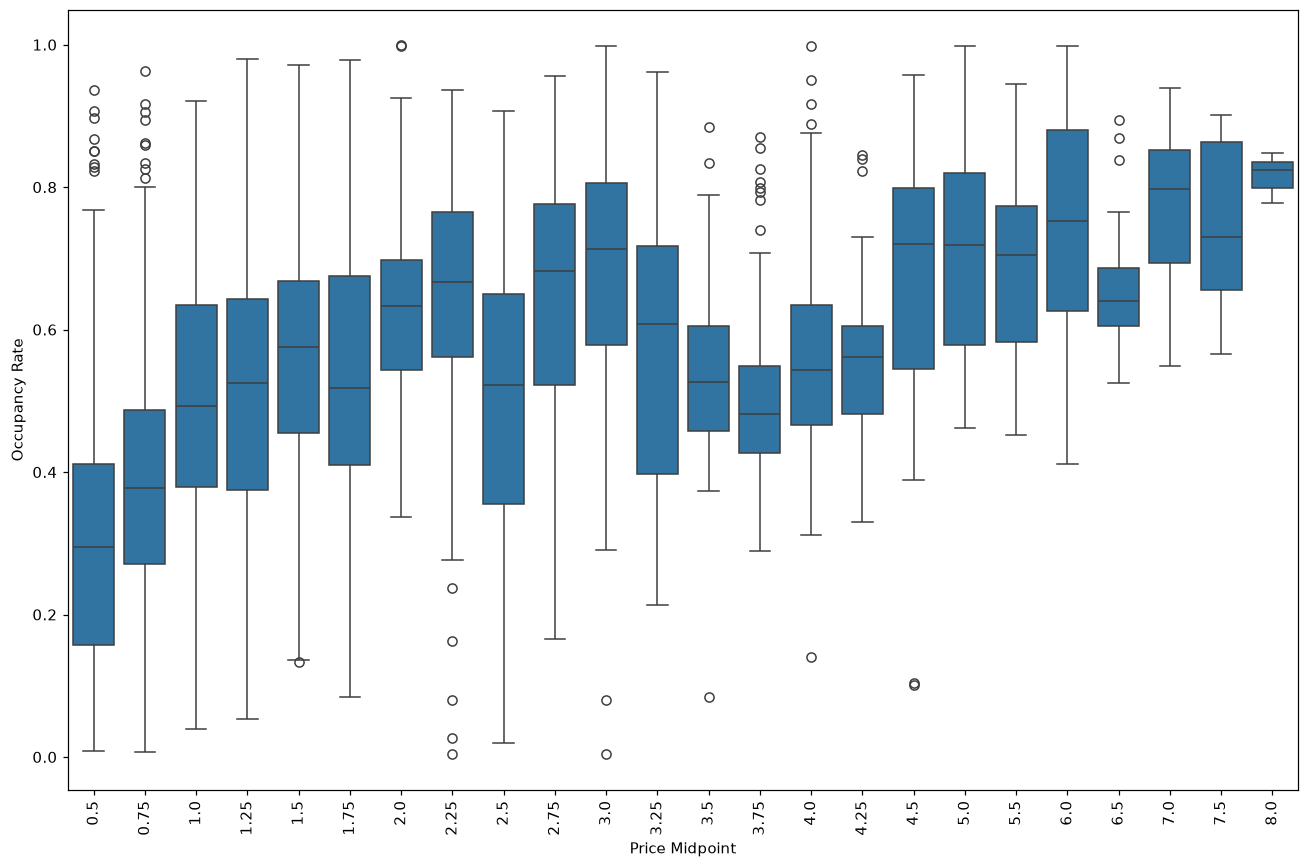

In [133]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.boxplot(data=df, x='price_midpoint', y='occupancy_rate', ax=ax)
ax.set_xlabel('Price Midpoint')
ax.set_ylabel('Occupancy Rate')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [144]:
# P1: flag spaces whose occupancy is above their price group's boxplot upper whisker (Q3 + 1.5×IQR) as high outliers

g = df.groupby('price_midpoint')['occupancy_rate']

q1 = g.transform('quantile', 0.25)
q3 = g.transform('quantile', 0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

high_outliers = df[df['occupancy_rate'] > upper_fence]

high_outliers[['SpaceID', 'price_midpoint', 'occupancy_rate']]



,SpaceID,price_midpoint,occupancy_rate
361,CB1393,0.75,0.905031
362,CB1394,0.75,0.894813
363,CB1396,0.75,0.833493
364,CB1397,0.75,0.916439
365,CB1397A,0.75,0.858984
366,CB1399,0.75,0.861405
524,CB170,0.50,0.867505
525,CB171,0.50,0.906629
526,CB172,0.50,0.936121
527,CB173,0.50,0.828957


In [145]:
# P2: group high outliers by BlockFace, count them and list their IDs, then compare to total spaces per BlockFace to get the outlier share
bf_groups = (
    high_outliers.groupby('BlockFace')
    .agg(n_outliers=('SpaceID', 'count'),
         space_ids=('SpaceID', list),
         mean_occ=('occupancy_rate', 'mean'))
    .sort_values('n_outliers', ascending=False)
)

bf_total = df.groupby('BlockFace')['SpaceID'].count().rename('total_spaces')
bf_groups = bf_groups.join(bf_total)
bf_groups['share_outlier'] = bf_groups['n_outliers'] / bf_groups['total_spaces']

bf_groups

,n_outliers,space_ids,mean_occ,total_spaces,share_outlier
BlockFace,,,,,
800 HOPE ST,6,"[CB1393, CB1394, CB1396, CB1397, CB1397A, CB1399]",0.878361,6,1.000000
800 CESAR E CHAVEZ AVE,4,"[CC1023, CC1025, CC1027, CC1029]",0.850573,6,0.666667
600 MAIN ST,4,"[CB3701, CB3702B, CB3703, CB3704]",0.812871,4,1.000000
400 PICO BLVD,4,"[CB170, CB171, CB172, CB173]",0.884803,9,0.444444
1000 MAPLE AVE,2,"[CB981, CB984]",0.831212,6,0.333333
700 SAN JULIAN ST,2,"[CB2223, CB2227]",0.826789,6,0.333333
301 6TH ST,2,"[CB3113, CB3113A]",0.882090,16,0.125000
400 11TH ST,2,"[CB2114A, CB2115]",0.998782,13,0.153846
700 YALE ST,2,"[CT436A, CT449A]",0.819303,9,0.222222
